# Process Parquet Files - ILIT0016 (Autoencoder Dent Detection)

This notebook post-processes per-frame autoencoder (`ae`) dent-detection results for an
inspection run and (optionally) inserts the resulting candidate anomalies back into the
inspection database.

## Workflow

1. **Configure run** — set the `inspection_id`, `workflow_name`, the list of tracks
   that were scored (`track_lists`), the `run_number`, and the target `environment`.
2. **Download results** — pull all per-frame parquet files produced by the
   `dent_detection_ae` workflow from the S3 track-runs bucket (configured in
   the `download_s3_folder(...)` call below) into a local results directory.
3. **Aggregate detections** — read every parquet file with `create_df`, parse the
   per-track probability vector, drop frames whose maximum probability is below a
   small floor, and compute the `max_prob` / `max_prob_track` columns (with optional
   noisy-track exclusion).
4. **Visualize** — plot a histogram of the winning track index over
   high-confidence frames to sanity-check which tracks fire and spot noisy ones.
5. **Filter candidates** — `keep_row_by_probs` keeps frames that look like real
   dents based on per-track probability thresholds (with chronically noisy
   probability indices excluded), then `filter_close_detections` collapses
   neighbouring detections (within 0.2 m of each other) to the single
   highest-probability frame.
6. **Persist** — save the de-duplicated `final_df` to a parquet file alongside the
   notebook for downstream review.
7. **Inspect** — `gen_image` rebuilds the arm-angle image around each kept
   detection so a human can quickly review the candidates.
8. **Insert anomalies** — using `ilipy` / `ilipyutils`, convert each surviving
   detection into an `ML_PRED` anomaly tagged with the model's confidence bin
   (`get_decimal_range` → `threshold_bin-{lower}-{upper}`) and upload it to
   the inspection. ⚠️ The `feature_insert.insert_ml_pred(...)` call in this
   section is **live** — running that cell writes anomalies to the target
   inspection on `environment`. Uploads cannot be undone without a separate
   cleanup step, so double-check `inspection_id`, `environment`, `model_info`,
   and `final_df` before running it.

## Key conventions

- **`prob` column** — a list of per-track probabilities, one entry per index in
  `track_lists`. The list index is a *probability index*, not an actual track id.
- **`prob_idx_to_track`** — converts a probability index back to the real track
  index used by `ilipy` (`TrackIndex`). Always apply this before calling any
  `ilipy` API that expects a physical track.
- **`start` / `end`** — view distances (meters) bounding a candidate detection.

## 1. Setup & configuration

Set the inspection-specific knobs in the cell below before running anything else:

| Variable | What to set it to |
| --- | --- |
| `inspection_id` | Inspection UUID (e.g. `0AXVHCA77S1` → ilit16). |
| `workflow_name` | Track-run workflow that produced the parquet files (default `dent_detection_ae`). |
| `track_lists` | Physical track ids that were scored, in the same order the model emitted probabilities. The list index is the *probability index* used everywhere downstream. |
| `run_number` | Free-form label appended to the local image cache (`./data/ilit{run_number}`). |
| `environment` | `ilipy` environment for `Session` (`prod`, `staging`, …). |

`prob_idx_to_track(prob_idx)` is the canonical mapping from a probability
index back to a physical `TrackIndex`. Always go through it before calling
any `ilipy` API that expects a real track id.

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import ast
import numpy as np
import sys
import seaborn as sns
# /home/sayakdg/ILI_workflow_dev/backuo/ILIWorkflows/workflows
# workflow_root = Path("/home/sayakdg/ILI_workflow_dev/backuo/ILIWorkflows/")
# if str(workflow_root) not in sys.path:
#     sys.path.append(str(workflow_root))

# from ilipy import Session, ClipTypes, OdometerTicks, ViewDistance
# from ilipy.database import DistanceCorrelation
# from ilipy.sensors import ArmAngleLookup

In [2]:

inspection_id = "0AXVHCA77S1"  # ilit16
angle_profiles = ["0"]
workflow_name = "dent_detection_ae"

track_lists = list(range(22))
num_tracks = len(track_lists)
run_number = "17"
environment = "research"  # unused if you stay local

results_dir = "/home/sayakdg/stats-experiments/dent_ae_v4.0"

In [3]:
root = Path(results_dir)
data_files = sorted(root.rglob("*.parquet"))

In [4]:
len(data_files), data_files

(853,
 [PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_-4.406561959689965_0000000000.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000000000.0_0000000250.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000000250.0_0000000500.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000000500.0_0000000750.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000000750.0_0000001000.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000001000.0_0000001250.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0/distance_0000001250.0_0000001500.0_framestep_000001_margin_0.15.parquet'),
  PosixPath('/home/sayakdg/stats-experiments/dent_ae_v4.0

## 3. Aggregate detections into a single DataFrame

`create_df` walks every file in `data_files`, parses the stringified `prob`
column into a real list with `parse_prob`, drops frames whose maximum
probability is below 0.05 (pure noise), and adds `max_prob` /
`max_prob_track` columns. Pass `frame_range=(start, end)` to restrict to a
specific frame window, or `exclude_prob_indicies=[...]` to ignore noisy
probability indices when picking the per-frame max.

The result is bound to `all_dfs` and displayed for a first look.

In [5]:
# Function to parse probability strings into actual lists if needed
def parse_prob(prob_str):
    """Convert string representation of list to actual list if needed"""
    if isinstance(prob_str, str):
        try:
            return ast.literal_eval(prob_str)
        except:
            return []
    return prob_str


def create_df(data_files, frame_range=None, th=0.05, exclude_prob_indicies=[]):
    """Aggregate every per-frame parquet file into a single detection DataFrame.

    Each parquet file produced by the ``dent_detection_ae`` workflow contains one
    row per frame with a stringified list of per-track probabilities under the
    ``prob`` column. This helper:

      * optionally restricts the files to a ``frame_range`` (start, end) window
        based on the file naming convention ``frames_{start:012d}_{end:012d}``;
      * parses ``prob`` strings into Python lists via :func:`parse_prob`;
      * drops frames whose maximum probability is at or below ``th`` (default
        0.05, i.e. pure noise);
      * computes ``max_prob`` and ``max_prob_track`` columns, ignoring any
        probability indices listed in ``exclude_prob_indicies`` (useful for
        suppressing chronically noisy tracks).

    Args:
        data_files: Iterable of parquet file paths to read (e.g. the
            ``data_files`` list produced by globbing ``results_dir``).
        frame_range: Optional ``(start_frame, end_frame)`` tuple (inclusive of
            ``start``, matching parquet filename prefix). When ``None`` all
            available parquet files are loaded.
        th: Per-frame probability floor. A frame is kept only if at least one
            track's probability exceeds ``th``; otherwise it is dropped as
            noise (default 0.05).
        exclude_prob_indicies: Probability-array indices to ignore when
            computing ``max_prob`` / ``max_prob_track``. These are *probability*
            indices into ``track_lists``, not physical track ids.

    Returns:
        ``pandas.DataFrame`` concatenated across all matching parquet files with
        the additional ``max_prob`` and ``max_prob_track`` columns. An empty
        DataFrame is returned when no valid data is found.
    """
    if frame_range is None:
        data_files_range = [f for f in data_files]
    else:
        data_files_range = [f for f in data_files if f.name.startswith(f"frames_{frame_range[0]:012d}_{frame_range[1]:012d}")]

    def read_and_validate(path):
        df = pd.read_parquet(path)
        if df.empty:
            return df
        df['prob'] = df['prob'].apply(parse_prob)
        df = df[df['prob'].apply(lambda probs: any(p > th for p in probs))] 
        
        
        def max_prob_excluding_track(probs, exclude_indices=exclude_prob_indicies):
            if probs is None or len(probs) == 0:
                return 0, -1
            valid = [(p, i) for i, p in enumerate(probs) if i not in exclude_indices]
            if not valid:
                return 0, -1
            max_p, max_i = max(valid, key=lambda x: x[0])
            return max_p, max_i
        df['max_prob'] = df['prob'].apply(lambda probs: max_prob_excluding_track(probs)[0])
        df['prob'] = df['prob'].apply(lambda p: list(p) if p is not None else [])
        df['max_prob_track'] = df['prob'].apply(lambda probs: max_prob_excluding_track(probs)[1])
        return df
    
    dfs = [df for df in (read_and_validate(path) for path in data_files_range) if not df.empty]

        # Handle case where all DataFrames were empty or had errors
    if not dfs:
        print(f"No valid data found for frame_range={frame_range}")
        return pd.DataFrame()
    
    return pd.concat(dfs) if len(dfs) > 1 else dfs[0]

In [6]:
all_dfs = create_df(data_files)
display(all_dfs)

,start,end,prob,max_prob,max_prob_track
0,-4.556562,-4.256562,"[0.0, 0.0006, 0.0015, 1e-04, 0.0, 0.0002, 0.0,...",0.0899,21
1,-4.406562,-4.106562,"[0.0092, 0.5344, 0.0127, 0.0694, 0.0209, 0.002...",0.5344,1
2,-4.256562,-3.956562,"[0.0122, 0.0142, 0.0081, 0.0073, 0.0045, 0.002...",0.0668,11
5,-3.806562,-3.506562,"[0.0114, 0.0016, 0.0139, 0.0065, 0.0004, 0.003...",0.6040,9
27,-0.506562,-0.206562,"[0.0002, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0....",0.2311,21
...,...,...,...,...,...
1259,212938.700000,212939.000000,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.7900,19
1283,212942.300000,212942.600000,"[0.0, 0.0002, 0.006, 0.4635, 0.6686, 0.0008, 0...",0.6686,4
1304,212945.450000,212945.750000,"[1e-04, 0.0, 0.0004, 0.0, 0.0, 0.0002, 0.0, 1e...",0.3628,8
1323,212948.300000,212948.600000,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0.1550,21


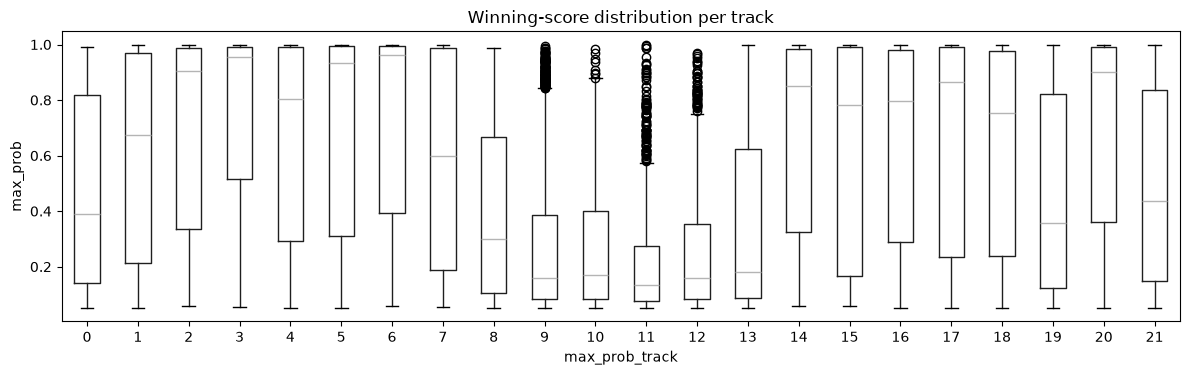

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
all_dfs.boxplot(column="max_prob", by="max_prob_track", ax=ax, grid=False)
ax.set_xlabel("max_prob_track")
ax.set_ylabel("max_prob")
ax.set_title("Winning-score distribution per track")
plt.suptitle("")
# mark IQR-flagged tracks
ticks = ax.get_xticklabels()
for lab in ticks:
    try:
        t = int(float(lab.get_text()))
    except ValueError:
        continue
plt.tight_layout()
plt.show()

## 4. Visualize raw detections

A quick sanity-check plot before any candidate filtering:

- a per-track histogram of `max_prob_track` (over frames with `max_prob > 0.9`)
  with the bin counts annotated above each bar, so you can spot tracks that
  fire unusually often (likely noise) or never (likely under-covered).

Use this plot to decide which probability indices to add to the
`exclude` set in the next section.

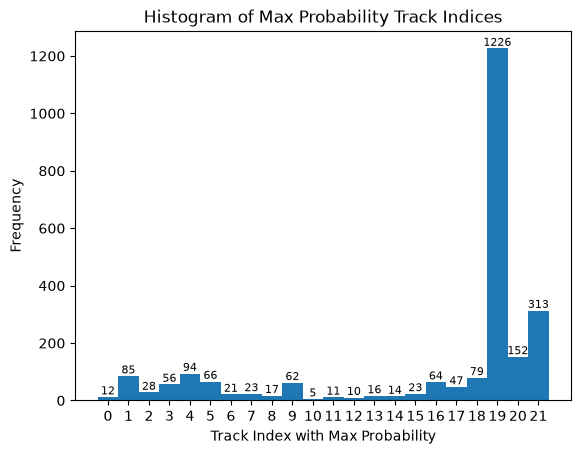

In [8]:
histogram_threshold = 0.9
counts, bin_edges, patches = plt.hist(
    all_dfs[all_dfs['max_prob'] > histogram_threshold]['max_prob_track'],
    bins=num_tracks,
    range=(-0.5, num_tracks - 0.5),
    align='mid',
)
for count, patch in zip(counts, patches):
    if count >= 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            f'{int(count)}',
            ha='center',
            va='bottom',
            fontsize=8,
        )
plt.xticks(range(num_tracks))
plt.xlabel('Track Index with Max Probability')
plt.ylabel('Frequency')
plt.title('Histogram of Max Probability Track Indices')
plt.show()

In [9]:
def outlier_tracks_log_iqr(counts, k=1.5):
    """Flag tracks whose win-count is an upper outlier on the log scale.

    ``counts[i]`` is how often probability index ``i`` was ``max_prob_track``.
    Zero-count bins are ignored for the fence (they cannot be upper outliers)
    and are never returned.

    Args:
        counts: 1-d array-like of non-negative bin counts, one per track.
        k: Tukey multiplier (default 1.5).

    Returns:
        dict with:
          exclude: list of integer track indices above Q3 + k * IQR
          log_counts, q1, q3, iqr, upper_fence
    """
    counts = np.asarray(counts, dtype=float)
    if counts.ndim != 1:
        raise ValueError("counts must be 1-d")
    if np.any(counts < 0):
        raise ValueError("counts must be non-negative")

    positive = counts > 0
    log_c = np.full(counts.shape, np.nan)
    log_c[positive] = np.log(counts[positive])

    sample = log_c[positive]
    if sample.size < 4:
        return {
            "exclude": [],
            "log_counts": log_c,
            "q1": np.nan,
            "q3": np.nan,
            "iqr": np.nan,
            "upper_fence": np.nan,
        }

    q1, q3 = np.percentile(sample, [25, 75])
    iqr = q3 - q1
    upper = q3 + k * iqr
    exclude = np.flatnonzero(positive & (log_c > upper)).tolist()

    return {
        "exclude": exclude,
        "log_counts": log_c,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "upper_fence": upper,
    }

{'exclude': [19],
 'log_counts': array([2.48490665, 4.44265126, 3.33220451, 4.02535169, 4.54329478,
        4.18965474, 3.04452244, 3.13549422, 2.83321334, 4.12713439,
        1.60943791, 2.39789527, 2.30258509, 2.77258872, 2.63905733,
        3.13549422, 4.15888308, 3.8501476 , 4.36944785, 7.11151212,
        5.02388052, 5.74620319]),
 'q1': np.float64(2.78774487769389),
 'q3': np.float64(4.324499574856873),
 'iqr': np.float64(1.5367546971629826),
 'upper_fence': np.float64(6.629631620601346)}

Track(s) to exclude: [19]
Cutoff for counts: 757.0


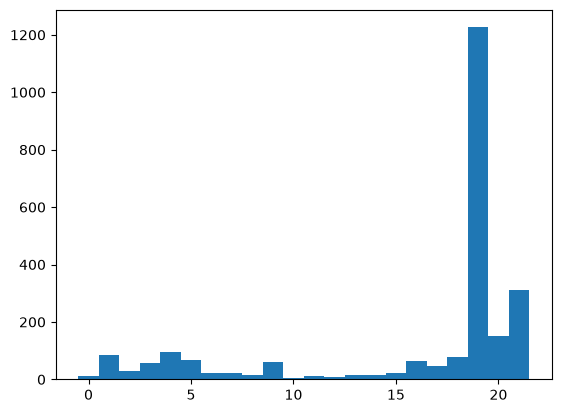

In [10]:
histogram_threshold = 0.9
counts, _, _ = plt.hist(
    all_dfs[all_dfs["max_prob"] > histogram_threshold]["max_prob_track"],
    bins=num_tracks,
    range=(-0.5, num_tracks - 0.5),
    align="mid",
)

result = outlier_tracks_log_iqr(counts)
display(result)
print('Track(s) to exclude:',result["exclude"])          # [] on this run
print('Cutoff for counts:',np.round(np.exp(result["upper_fence"])))  # fence back on the count scale

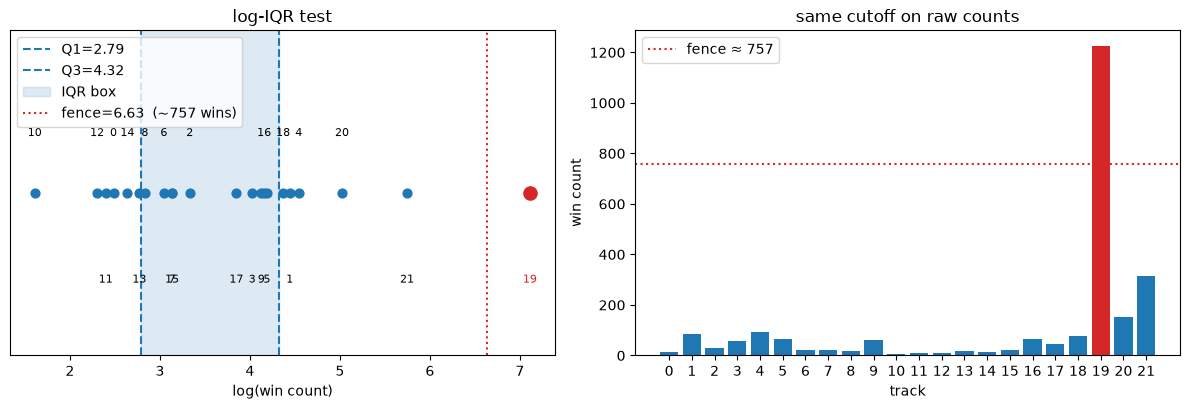

In [11]:
log_c = result["log_counts"]
tracks = np.arange(len(log_c))
ok = np.isfinite(log_c)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.scatter(log_c[ok], np.zeros(ok.sum()), s=40, zorder=3)
for t in tracks[ok]:
    color = "C3" if t in result["exclude"] else "k"
    if t in result["exclude"]:
        ax.scatter(log_c[t], 0, s=90, color="C3", zorder=4)
    # alternate above / below so nearby logs do not collide
    dy = 0.04 if (t % 2 == 0) else -0.06
    ax.annotate(
        str(t),
        (log_c[t], dy),
        ha="center",
        va="bottom" if dy > 0 else "top",
        fontsize=8,
        color=color,
    )
ax.axvline(result["q1"], color="C0", ls="--", label=f"Q1={result['q1']:.2f}")
ax.axvline(result["q3"], color="C0", ls="--", label=f"Q3={result['q3']:.2f}")
ax.axvspan(result["q1"], result["q3"], color="C0", alpha=0.15, label="IQR box")
ax.axvline(result["upper_fence"], color="C3", ls=":",
           label=f"fence={result['upper_fence']:.2f}  (~{np.exp(result['upper_fence']):.0f} wins)")
ax.set_yticks([])
ax.set_ylim(-0.12, 0.12)
ax.set_xlabel("log(win count)")
ax.set_title("log-IQR test")
ax.legend(loc="upper left")

ax = axes[1]
colors = ["C3" if i in result["exclude"] else "C0" for i in tracks]
ax.bar(tracks, np.exp(np.nan_to_num(log_c)), color=colors)
ax.axhline(np.exp(result["upper_fence"]), color="C3", ls=":",
           label=f"fence ≈ {np.exp(result['upper_fence']):.0f}")
ax.set_xticks(tracks)
ax.set_xlabel("track")
ax.set_ylabel("win count")
ax.set_title("same cutoff on raw counts")
ax.legend()

plt.tight_layout()
plt.show()

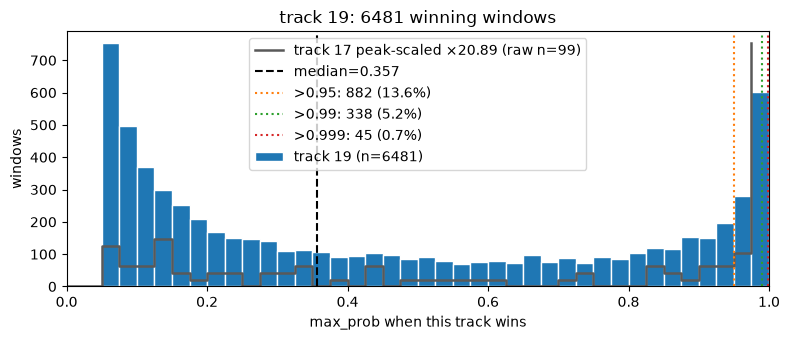

track 19: 99th percentile = 0.9983


In [35]:
outlier_tracks = result["exclude"]
thresholds = (0.95, 0.99, 0.999)
colors = ("C1", "C2", "C3")
bins = np.linspace(0, 1, 41)
peak_frac = 1   # 0.5 → overlay peak is half the blue peak
rng = np.random.default_rng(0)

eligible = [
    t for t in range(num_tracks)
    if t not in outlier_tracks
    and (all_dfs["max_prob_track"] == t).sum() >= 20
]
if not eligible:
    raise RuntimeError("no non-outlier track with enough wins to overlay")
ref_track = int(rng.choice(eligible))
ref_maxima = all_dfs.loc[all_dfs["max_prob_track"] == ref_track, "max_prob"].to_numpy(dtype=float)
ref_hist, _ = np.histogram(ref_maxima, bins=bins)
ref_n = len(ref_maxima)

if not outlier_tracks:
    print("IQR flagged nobody")
else:
    fig, axes = plt.subplots(len(outlier_tracks), 1, figsize=(8, 3.5 * len(outlier_tracks)), squeeze=False)
    for ax, t in zip(axes.ravel(), outlier_tracks):
        maxima = all_dfs.loc[all_dfs["max_prob_track"] == t, "max_prob"].to_numpy(dtype=float)
        n = len(maxima)
        hist, _ = np.histogram(maxima, bins=bins)
        if ref_hist.max() == 0:
            overlay = ref_hist
            scale = 0.0
        else:
            scale = peak_frac * hist.max() / ref_hist.max()
            overlay = ref_hist * scale

        ax.bar(bins[:-1], hist, width=np.diff(bins), align="edge",
               color="C0", edgecolor="white", label=f"track {t} (n={n})")
        ax.step(bins[:-1], overlay, where="post", color="0.35", lw=1.8,
                label=f"track {ref_track} peak-scaled ×{scale:.2f} (raw n={ref_n})")
        ax.axvline(np.median(maxima), color="k", ls="--", label=f"median={np.median(maxima):.3f}")
        for th, c in zip(thresholds, colors):
            n_above = int((maxima > th).sum())
            ax.axvline(th, color=c, ls=":", label=f">{th}: {n_above} ({n_above/n:.1%})")
        ax.set_xlim(0, 1)
        ax.set_xlabel("max_prob when this track wins")
        ax.set_ylabel("windows")
        ax.set_title(f"track {t}: {n} winning windows")
        ax.legend()
    plt.tight_layout()
    plt.show()

for t in outlier_tracks:
    maxima = all_dfs.loc[all_dfs["max_prob_track"] == t, "max_prob"].to_numpy(dtype=float)
    print(f"track {t}: 99th percentile = {np.percentile(maxima, 99):.4f}")

## 5. Filter candidates and persist

Cut `all_dfs` down to a clean set of unique candidate detections.

- **`keep_row_by_probs`** drops the chronically noisy probability indices
  (`{20, 21}` for this run) and keeps frames whose remaining tracks satisfy
  one of three OR-ed thresholds (currently `0.9 / 0.95 / 0.99` — see the
  function docstring for the exact rules and how to retune them). Because
  `all_dfs` was built without exclusions (so the diagnostic histogram can
  surface noisy tracks), `max_prob` / `max_prob_track` are then recomputed on
  the kept rows using the same `exclude_tracks_set`, guaranteeing the winning
  track handed to the upload step is never an excluded index.
- **`filter_close_detections`** sorts the survivors by view distance and
  collapses any cluster of detections within `distance_threshold` (default
  0.2 m) down to the single highest-`max_prob` row, producing `final_df`.
- The last cell saves `final_df` to
  `./insp_{inspection_id}_final_df_ae.parquet` so the section below (and any
  downstream review notebook) can reload it without re-running the upstream
  steps.

Filtered DF size: 655


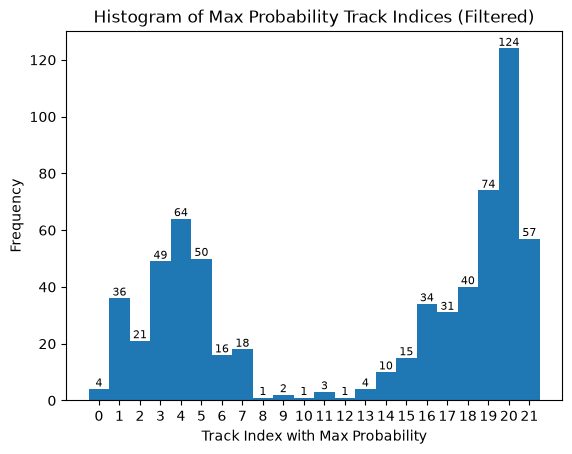

In [41]:
multi_track_th1, multi_track_th2, single_track_th = 0.9, 0.95, 0.99
strict_single_track_th = 0.998
exclude_tracks_set = set()
strict_tracks_set = set(result["exclude"])  # e.g. {19}

def keep_row_by_probs(probs):
    """Keep a frame using ordinary-track rules, plus a lone high hit on IQR tracks.

    Strict / IQR indices (``strict_tracks_set``) are omitted from every
    agreement count. They cannot create a 3×0.9, a 2×0.95, or a second
    0.99 single. They also cannot veto an ordinary single.

    A row is kept when **any** of these hold:

      * at least 3 *ordinary* tracks exceed ``multi_track_th1`` (0.9);
      * at least 2 *ordinary* tracks exceed ``multi_track_th2`` (0.95);
      * exactly 1 *ordinary* track exceeds ``single_track_th`` (0.99);
      * no ordinary single, and exactly 1 strict track exceeds
        ``strict_single_track_th`` (0.999) — extra defects on the IQR arm.

    Args:
        probs: Per-track probabilities for one frame.

    Returns:
        ``True`` if the frame is a candidate, ``False`` otherwise.
    """
    if not probs:
        return False

    ordinary = [(i, p) for i, p in enumerate(probs) if i not in strict_tracks_set]
    n3 = sum(1 for _, p in ordinary if p > multi_track_th1)
    n2 = sum(1 for _, p in ordinary if p > multi_track_th2)
    n1_ordinary = sum(1 for _, p in ordinary if p > single_track_th)

    if n3 >= 3 or n2 >= 2 or n1_ordinary == 1:
        return True

    n1_strict = sum(
        1
        for i, p in enumerate(probs)
        if i in strict_tracks_set and p > strict_single_track_th
    )
    if n1_ordinary == 0 and n1_strict == 1:
        return True
    return False
    
filtered_df = all_dfs[all_dfs['prob'].apply(keep_row_by_probs)].copy()

# Recompute max_prob / max_prob_track with the SAME exclusion set used for the
# keep decision. ``all_dfs`` is built without exclusions (so the diagnostic
# histogram above can reveal noisy tracks), so we recompute here to guarantee
# the winning track fed to filter_close_detections and the upload step can
# never be one of the excluded noisy indices.
def max_prob_excluding_track(probs):
    valid = []
    for i, p in enumerate(probs):
        if i in strict_tracks_set and p <= strict_single_track_th:
            continue
        valid.append((p, i))
    if not valid:
        return 0, -1
    return max(valid, key=lambda x: x[0])

# Assign the two columns separately so max_prob_track stays an int (a single
# pd.Series assignment would coerce both to float, breaking track_lists[idx]).
_recomputed = filtered_df['prob'].apply(max_prob_excluding_track)
filtered_df['max_prob'] = _recomputed.apply(lambda t: t[0])
filtered_df['max_prob_track'] = _recomputed.apply(lambda t: t[1]).astype(int)
print(f"Filtered DF size: {len(filtered_df)}")
counts, bin_edges, patches = plt.hist(
    filtered_df['max_prob_track'],
    bins=num_tracks,
    range=(-0.5, num_tracks - 0.5),
    align='mid',
)
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            f'{int(count)}',
            ha='center',
            va='bottom',
            fontsize=8,
        )
plt.xticks(range(num_tracks))
plt.xlabel('Track Index with Max Probability')
plt.ylabel('Frequency')
plt.title('Histogram of Max Probability Track Indices (Filtered)')
plt.show()

In [37]:
def filter_close_detections(df, distance_threshold=0.2):
    """
    Filter out detections that are close to each other.
    When multiple detections are within distance_threshold, keep only the one with highest max_prob.
    
    Args:
        df: DataFrame with 'start' and 'max_prob' columns
        distance_threshold: Maximum allowed distance between starts (default 0.2)
        
    Returns:
        DataFrame with filtered rows
    """
    if len(df) <= 1:
        return df
    
    # Sort by start descending
    df_sorted = df.sort_values(by='start', ascending=False).reset_index(drop=True)
    
    # Group detections within threshold
    starts = df_sorted['start'].values
    probs = df_sorted['max_prob'].values
    
    groups = []
    current_group = [0]
    
    for i in range(1, len(df_sorted)):
        # Check if within threshold of the first item in current group
        if starts[current_group[0]] - starts[i] < distance_threshold:
            current_group.append(i)
        else:
            # Finalize current group, keep highest prob
            groups.append(current_group)
            current_group = [i]
    
    # Don't forget the last group
    groups.append(current_group)
    
    # For each group, keep only the one with max prob
    kept_indices = []
    for group in groups:
        max_prob_idx = group[np.argmax(probs[group])]
        kept_indices.append(max_prob_idx)
    
    return df_sorted.iloc[kept_indices].reset_index(drop=True)

final_df = filter_close_detections(filtered_df)
print(f"Original df: {len(filtered_df)} rows")
print(f"final df: {len(final_df)} rows")

Original df: 641 rows
final df: 632 rows


In [19]:
#save final_df
final_df.to_parquet(f"./insp_{inspection_id}_final_df_ae_no_track_filter.parquet", index=False)
display(final_df)

,start,end,prob,max_prob,max_prob_track
0,212688.70,212689.00,"[0.0, 0.0, 0.0, 1e-04, 0.9163, 0.9951, 0.1783,...",0.9951,5
1,212632.45,212632.75,"[0.0004, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0....",0.9959,21
2,212518.60,212518.90,"[0.0, 0.0, 0.0, 0.0, 0.0002, 0.0, 0.0, 0.0, 0....",0.9846,10
3,212008.70,212009.00,"[0.0, 0.001, 0.9611, 0.9895, 0.0065, 0.0, 0.00...",0.9895,3
4,211794.10,211794.40,"[0.0, 0.0, 0.0, 0.9978, 0.9999, 0.9948, 1e-04,...",0.9999,4
...,...,...,...,...,...
627,1369.70,1370.00,"[0.002, 0.0175, 0.9311, 0.995, 0.9907, 0.0039,...",0.9950,3
628,962.85,963.15,"[1e-04, 0.0, 0.0, 0.0, 1e-04, 0.0, 0.0, 0.0, 0...",0.9936,19
629,507.80,508.10,"[0.0, 1e-04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",0.9992,18
630,93.45,93.75,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1e-04...",0.9971,17


## 6. Visual review of candidate detections

Render the arm-angle image around each surviving detection in `final_df` so
you can eyeball the candidates before uploading them. `gen_image` pulls the
arm angles for a `length`-meter window starting at the detection's view
distance, samples them at every 10 odometer ticks, and (when `show_im=True`)
plots the result with `imshow` using the `inferno` colormap.

The loop below renders the first 10 rows of `final_df`; bump the `.head(N)`
or remove it entirely to review the full set.

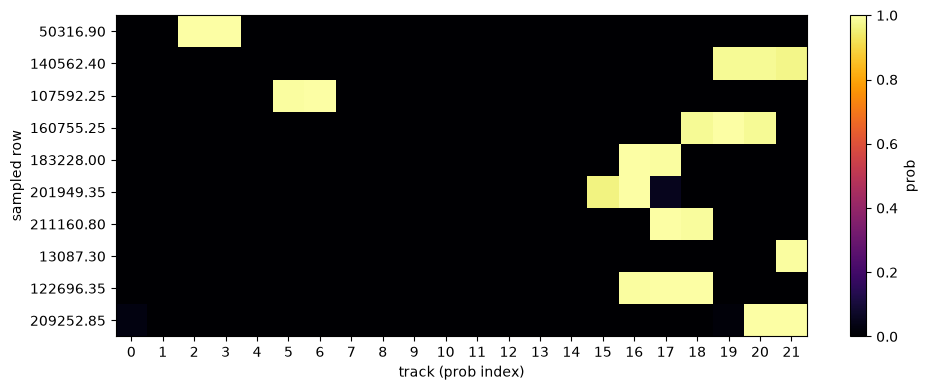

In [23]:
import numpy as np
import matplotlib.pyplot as plt

n = min(10, len(final_df))
sample = final_df.sample(n, replace=False)
mat = np.vstack([np.asarray(p, dtype=float) for p in sample["prob"]])
n_tracks = mat.shape[1]

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(mat, cmap="inferno", vmin=0, vmax=1, aspect="auto")
ax.set_xlabel("track (prob index)")
ax.set_ylabel("sampled row")
ax.set_xticks(range(n_tracks))
ax.set_xticklabels(range(n_tracks))
ax.set_yticks(range(n))
ax.set_yticklabels([f"{s:.2f}" for s in sample["start"]])
fig.colorbar(im, ax=ax, label="prob")
plt.tight_layout()
plt.show()

In [21]:
display(final_df)

,start,end,prob,max_prob,max_prob_track
0,212688.70,212689.00,"[0.0, 0.0, 0.0, 1e-04, 0.9163, 0.9951, 0.1783,...",0.9951,5
1,212632.45,212632.75,"[0.0004, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0....",0.9959,21
2,212518.60,212518.90,"[0.0, 0.0, 0.0, 0.0, 0.0002, 0.0, 0.0, 0.0, 0....",0.9846,10
3,212008.70,212009.00,"[0.0, 0.001, 0.9611, 0.9895, 0.0065, 0.0, 0.00...",0.9895,3
4,211794.10,211794.40,"[0.0, 0.0, 0.0, 0.9978, 0.9999, 0.9948, 1e-04,...",0.9999,4
...,...,...,...,...,...
627,1369.70,1370.00,"[0.002, 0.0175, 0.9311, 0.995, 0.9907, 0.0039,...",0.9950,3
628,962.85,963.15,"[1e-04, 0.0, 0.0, 0.0, 1e-04, 0.0, 0.0, 0.0, 0...",0.9936,19
629,507.80,508.10,"[0.0, 1e-04, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...",0.9992,18
630,93.45,93.75,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1e-04...",0.9971,17


## Insert Anomalies

Convert each surviving detection in `final_df` into a reviewable anomaly in
the inspection database. Make sure the setup and filtering sections above have
been run first so that `final_df`, `inspection_id`, and `prob_idx_to_track` are
defined, then run this section top-to-bottom (it defines `get_decimal_range`
before using it).

The cells in this section do, in order:

1. **Open an `ilipy` session and load the latest model** — connect to the
   inspection on `environment` (`prod` by default), open a `DistanceCorrelation`
   for view-distance ↔ odometer-tick conversions, instantiate the
   `Bookmarks` / `FeatureInsert` interfaces, and pull the latest registered
   `ili_custom_data` model class (used to attach a confidence score to each
   anomaly).
2. **`get_decimal_range`** — helper that buckets the model's confidence score
   into a 1%-wide bin (e.g. `0.873 → (0.87, 0.88)`) for tag-based grouping in
   review tools.
3. **Build the bounding cube and pick the model definition** — define a
   `GeometryCubeParameters` of ±15° in cube and probe-scan angle and a 1.9 mm
   thickness centred on the 200 mm radial position, and look up the
   `Dent-Detection-v4` entry in the ML model registry.
4. **Iterate over `final_df` and stage each upload** — for every row,
   convert the probability index `max_prob_track` to a physical track via
   `prob_idx_to_track`, translate the `start` / `end` view distances into
   odometer ticks for that track, build an `extra_tags` set with the
   confidence-bin label `threshold_bin-{lower}-{upper}`, and instantiate the
   `latest_model(ml_confidence_score=max_prob)` payload.

> **⚠️ The `feature_insert.insert_ml_pred(...)` call below is LIVE.** Running
> that cell writes one anomaly per row of `final_df` to the target inspection
> on `environment` (`prod` by default). Double-check `inspection_id`,
> `environment`, `model_info`, and the contents of `final_df` before running
> it — uploads cannot be undone without a separate cleanup step. Comment out
> the `feature_insert.insert_ml_pred(...)` block if you only want a dry run.

The remaining cells in this section (the long commented-out blocks at the
bottom) preserve the older, hand-rolled `AnomalyInfo` / `GeometryBoundingCube`
construction path for reference and are kept only as documentation of how the
upload used to be done before `FeatureInsert` was available.

In [ ]:
from ilipy import Session, TrackIndex, ViewDistance
from ilipy.channeldata import ImageProfile
from ilipy.features import Bookmarks
from ilipyutils.ml_features.base import get_ml_models_info_list, AnomalyStatus
from ilipyutils.ml_features.insert import FeatureInsert, GeometryCubeParameters
from ili_custom_data.load_model import ModelDataLoader
from ilipy.database import DistanceCorrelation

session = Session(environment=environment)
session.set_active_inspection(inspection_id)
dist_corr = DistanceCorrelation(session)
bookmarks_interface = Bookmarks(session=session)
feature_insert = FeatureInsert(session=session, bookmarks_interface=bookmarks_interface)
latest_model = ModelDataLoader.get_latest_model()

In [ ]:
def get_decimal_range(value):
    """Return the 0.01-wide bucket that ``value`` falls into.

    The lower bound is ``value`` truncated (floored) to two decimal places;
    the upper bound is ``lower + 0.01``. Used downstream to tag each anomaly
    with a confidence-bin label of the form
    ``f"threshold_bin-{lower}-{upper}"`` so detections can be grouped by
    1%-wide score ranges in review tools.

    Examples:
        ``0.56`` → ``(0.56, 0.57)``
        ``0.789`` → ``(0.78, 0.79)``
        ``0.9999`` → ``(0.99, 1.0)``

    Args:
        value (float): A confidence score, typically in ``[0, 1]``.

    Returns:
        tuple[float, float]: ``(lower, upper)`` bounds of the bucket
        containing ``value``, both rounded to 2 decimal places.
    """
    lower = int(value * 100) / 100
    upper = round(lower + 0.01, 2)

    return lower, upper

In [ ]:
cube_params = GeometryCubeParameters(
tlbr_cube_angle_rad=(np.deg2rad(-15), np.deg2rad(15)),
tlbr_probe_scan_angle_rad=(np.deg2rad(-15), np.deg2rad(15)),
tlbr_radial_position_mm=(200-(1.9/2), 200+(1.9/2)),
)
model_info = next(
    model
    for model in get_ml_models_info_list()
    if model.model_name == "Dent-Detection-v4"
)
model_info

In [ ]:
i=0
for i, row in final_df.iterrows():

        print(f"uploading row {i+1} of {len(final_df)}")
        profile = ImageProfile.ZeroAngle 
        vd_start, vd_end, _ , max_prob, max_prob_track = row['start'], row['end'], row['prob'], row['max_prob'], row['max_prob_track']
        actual_track_idx = prob_idx_to_track(max_prob_track)

        start_frame_odo_ticks = dist_corr.get_odometer_ticks_from_view_distance(TrackIndex(actual_track_idx), ViewDistance(vd_start)).value
        end_frame_odo_ticks = dist_corr.get_odometer_ticks_from_view_distance(TrackIndex(actual_track_idx), ViewDistance(vd_end)).value
        model_instance = latest_model(
        ml_confidence_score=max_prob,)
        lower_bound, upper_bound = get_decimal_range(max_prob)
        extra_tags = {f"threshold_bin-{lower_bound}-{upper_bound}"}
        model_instance = latest_model(
        ml_confidence_score=max_prob,)
        print(extra_tags)


#         anomaly_info = feature_insert.insert_ml_pred(
#         inspection_id=inspection_id,
#         tlbr_track_indices=[actual_track_idx,actual_track_idx],
#         tlbr_odometer_ticks=(start_frame_odo_ticks, end_frame_odo_ticks),
#         cube_params=cube_params,
#         model_info=model_info,
#         anomaly_status=AnomalyStatus.REVIEW_DETECTION,
#         image_profile=profile,
#         extra_tags=extra_tags,
#         ili_custom_data=model_instance
#        )



